In [1]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = Path.cwd()

if not (BASE / "splits").is_dir():
    BASE = BASE / "output"

RESULT_DIR = BASE / "section_5"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

paths = {
    "adaptive": BASE / "section_4_4" /
        "adaptive_test_predictions_long.csv",
    "severity": BASE / "section_4_3" /
        "selected_severity_policy.json",
    "measurement": BASE / "section_4_4" /
        "selected_adaptive_strategy.json",
    "ranking": BASE / "section_4_5" /
        "selected_capacity_policy.json"
}

for name, path in paths.items():
    assert path.is_file(), f"Missing {name}: {path}"

with open(paths["severity"]) as f:
    severity_meta = json.load(f)

with open(paths["measurement"]) as f:
    measurement_meta = json.load(f)

with open(paths["ranking"]) as f:
    ranking_meta = json.load(f)

print("Severity:", severity_meta["selected_policy"])
print("Adaptive:", measurement_meta["selected_strategy"])
print("Ranking:", ranking_meta["selected_strategy"])

assert ranking_meta["selected_strategy"] == "HighProbability"
assert measurement_meta["selected_strategy"]["name"] == "Uncertainty"

df = pd.read_csv(
    paths["adaptive"],
    dtype={"row_id": str}
)

budgets = [0, 20, 40, 60, 80, 100]
capacities = [10, 20, 30, 40, 50]

assert len(df) == 1212 * len(budgets)
assert not df.duplicated(["Budget", "row_id"]).any()

reference_ids = set(
    df.loc[df["Budget"] == 0, "row_id"]
)

reference_labels = (
    df.loc[df["Budget"] == 0, ["row_id", "RiskLevel"]]
    .set_index("row_id")["RiskLevel"]
    .sort_index()
)

for b in budgets:
    subset = df[df["Budget"] == b]
    assert len(subset) == 1212
    assert set(subset["row_id"]) == reference_ids
    labels = subset.set_index("row_id")["RiskLevel"].sort_index()
    assert labels.equals(reference_labels)
    assert np.allclose(
        subset[["p_Low", "p_Mid", "p_High"]].sum(axis=1),
        1.0, atol=1e-6
    )

print("\nPASS: All adaptive budgets use the same records!")


Severity: {'name': 'Asym-20', 'type': 'cost', 'lambda': 20.0}
Adaptive: {'name': 'Uncertainty', 'type': 'entropy', 'alpha': 0.0}
Ranking: HighProbability

PASS: All adaptive budgets use the same records!


Review_Capacity,10,20,30,40,50
Measurement_Budget,,,,,
0,30.02,60.05,81.39,95.29,97.52
20,30.02,60.05,90.07,97.27,98.01
40,30.02,60.05,90.07,98.51,99.26
60,30.02,60.05,90.07,98.76,99.50
80,30.02,60.05,90.07,99.75,100.00
100,30.02,60.05,90.07,99.75,100.00


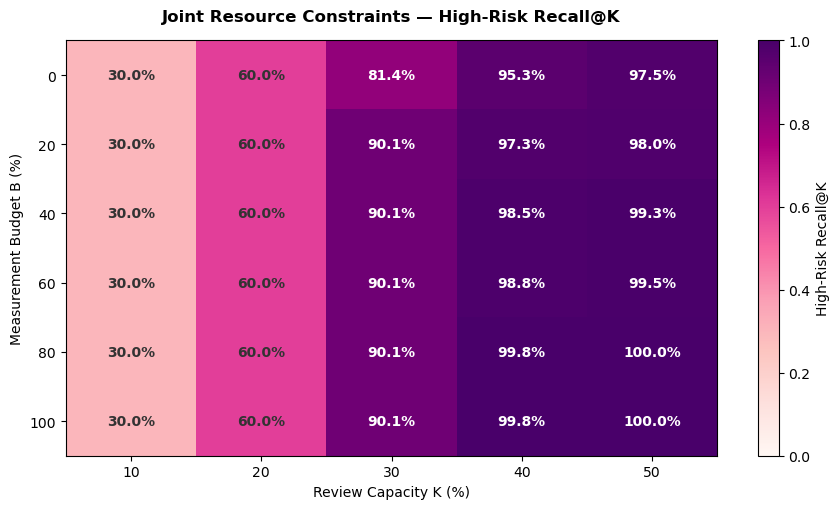

INTEGRATED B × K ANALYSIS COMPLETED!


In [2]:

rows = []

for b in budgets:
    part = df[df["Budget"] == b].copy()

    # HighProbability policy already selected on validation
    ranked = part.sort_values(
        ["p_High", "row_id"],
        ascending=[False, True],
        kind="mergesort"
    )

    n = len(ranked)
    total_high = int((ranked["RiskLevel"] == "High").sum())

    assert total_high == 403

    for k_percent in capacities:
        k = int(np.floor(n * k_percent / 100 + 1e-9))
        top = ranked.head(k)

        captured = int((top["RiskLevel"] == "High").sum())

        rows.append({
            "Measurement_Budget": b,
            "Review_Capacity": k_percent,
            "N_Reviewed": k,
            "Captured_High": captured,
            "Precision_at_K": captured / k,
            "High_Recall_at_K": captured / total_high
        })

integrated_df = pd.DataFrame(rows)

heatmap = integrated_df.pivot(
    index="Measurement_Budget",
    columns="Review_Capacity",
    values="High_Recall_at_K"
).loc[budgets, capacities]

# B=100% must match the official Section 4.5 results
assert integrated_df[
    integrated_df["Measurement_Budget"] == 100
]["Captured_High"].tolist() == [121, 242, 363, 402, 403]

display((heatmap * 100).round(2))

integrated_df.to_csv(
    RESULT_DIR / "integrated_BK_results.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(9, 5.2))

im = ax.imshow(
    heatmap.to_numpy(),
    cmap="RdPu",
    vmin=0,
    vmax=1,
    aspect="auto"
)

for i in range(len(budgets)):
    for j in range(len(capacities)):
        val = heatmap.iloc[i, j]
        ax.text(
            j, i, f"{100 * val:.1f}%",
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold",
            color="white" if val >= 0.65 else "#333333"
        )

ax.set_xticks(range(len(capacities)), capacities)
ax.set_yticks(range(len(budgets)), budgets)

ax.set_xlabel("Review Capacity K (%)")
ax.set_ylabel("Measurement Budget B (%)")

ax.set_title(
    "Joint Resource Constraints — High-Risk Recall@K",
    fontweight="bold",
    pad=14
)

fig.colorbar(
    im, ax=ax,
    label="High-Risk Recall@K"
)

plt.tight_layout()
plt.savefig(
    RESULT_DIR / "integrated_BK_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("INTEGRATED B × K ANALYSIS COMPLETED!")
